# Deep Learning Fundamentals — Intro Notebook
**Autonomous Systems B (2-week self-study block)**

This notebook introduces the core ideas needed for the first deep-learning lab:

- tensors and image shapes,
- feedforward neural networks,
- training loops and backpropagation,
- convolutional neural networks,
- hyperparameter experiments,
- reproducible scientific work.

The notebook is organized by **Week 1** and **Week 2**. Section 9 is an **optional extension / Week 3** topic.

> **Prerequisites:** basic Python, arrays, linear algebra, derivatives, and probability.  
> If Python/NumPy/PyTorch are new to you, review the course slides **DL 02 Python** before starting.

### Environment and reproducibility
Run the notebook **top-to-bottom**. Keep outputs visible and record the software versions used for your experiment.

In [ ]:
import random
import sys
import numpy as np
import torch
import torchvision

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Seed:", SEED)

---
# Week 1 — Foundations

## 1. Tensors & Arrays

**Concept:** Images are arrays. In PyTorch, image batches are usually represented as

$$
(N, C, H, W),
$$

where:

- $N$ = batch size,
- $C$ = number of channels,
- $H$ = image height,
- $W$ = image width.

A grayscale MNIST image has one channel, while an RGB image has three channels.

**Task 1.1 (Explain):**
- Given a batch shaped `(N, C, H, W)`, explain what each letter stands for.
- What shapes would you expect for grayscale vs. RGB images?

### Self-study checkpoint
Before continuing, make sure you can explain why a batch of 64 MNIST images has shape

$$
(64, 1, 28, 28).
$$

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 2 (Preliminaries), especially Sec. 2.1 Data Manipulation**: https://d2l.ai/

**Optional reading**
- Prince, *Understanding Deep Learning*, **Appendix B (Math)**; probability background is in **Appendix C**: https://udlbook.github.io/udlbook/

In [ ]:
img = torch.rand(28, 28)
print("Single grayscale image:", img.shape)

batch = torch.rand(64, 1, 28, 28)
print("Batch of grayscale images:", batch.shape)

rgb = torch.rand(16, 3, 64, 64)
print("Batch of RGB images:", rgb.shape)

**Your answer — Task 1.1**



Grayscale images have 1 channel, so their shape in the PyTorch format is (N, 1, H, W). RGB images have 3 channels red, green, and blue so their shape becomes (N, 3, H, W). The height and width stay the same;
 only the number of channels changes.

## 2. Feedforward Neural Networks (FFNN)

A hidden layer applies an affine transformation followed by a nonlinear activation. For a **row-vector** input,

$$
z = xW + b,
$$

followed by

$$
h = \phi(z).
$$

With ReLU,

$$
\phi(z) = \max(0,z).
$$

The nonlinearity is essential: several affine/linear layers without a nonlinear activation can be collapsed into one affine transformation.

> **PyTorch notation note:** In the mathematical row-vector convention above, $W$ has shape `(in_features, out_features)`.  
> `nn.Linear` stores its parameter as `weight` with shape `(out_features, in_features)` and internally computes
>
> $$
> y = xW^\top + b.
> $$
>
> Therefore, the matrix dimensions in the derivation and the shape of `layer.weight` appear transposed.

The final classification layer is usually left **without** an activation when using `nn.CrossEntropyLoss()`, because the loss expects raw **logits**.

**Task 2.1 (Reasoning):**
- Why do we need a nonlinear activation between hidden layers?<br>
  Nonlinear activation helps the network learn complex patterns that linear operations alone cannot learn
- How does matrix multiplication appear in a neural network?<br>
  Matrix multiplication combines inputs with weights, then adds biases to calculate each layer's output.
- What happens if all activations are removed?<br>
  The network becomes equivalent to a single linear layer with bias, making it unable to learn complex nonlinear patterns.

In [ ]:
import torch.nn as nn

def make_ffnn():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 128),
        nn.ReLU(),
        nn.Linear(128, 10)
    )

ffnn = make_ffnn()
ffnn

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)

### 2.2 From Linear Scores to Probabilities — Logits, Softmax, and Cross-Entropy

The final layer produces **logits**

$$
o = [o_1,\ldots,o_K].
$$

Softmax converts the logits into class probabilities:

$$
p_k
=
\frac{\exp(o_k)}
{\sum_{j=1}^{K}\exp(o_j)}.
$$

For one-hot targets, multiclass cross-entropy is

$$
\mathcal{L}
=
-\sum_{k=1}^{K}
y_k \log(p_k).
$$

Because only the correct class has target value $1$, this reduces to

$$
\mathcal{L}
=
-\log(p_y).
$$

Cross-entropy can also be interpreted as a **negative log-likelihood** for the correct class.

> **Important PyTorch detail:** `nn.CrossEntropyLoss()` expects raw logits. Do **not** add a `Softmax()` layer before it.

### Differences you will notice in Géron
Géron's Keras/TensorFlow examples often use:
- image layouts in **NHWC** form rather than PyTorch's typical **NCHW**,
- an explicit softmax output layer in model definitions.

In this notebook, PyTorch uses **NCHW** tensors and `CrossEntropyLoss()` receives raw logits.

**Task 2.2 (Reasoning):**
- Why is the denominator of softmax shared across all classes?<br>
The shared denominator makes sure all class probabilities add up to 1, so we can compare them fairly.
- Why does cross-entropy become large when the correct class receives a very small probability?<br>
Because cross-entropy uses the negative log of the correct class probability. A very small probability gives a large loss, meaning the prediction is poor.
- Why should we not apply softmax before `CrossEntropyLoss()`?<br>
Because PyTorch's CrossEntropyLoss() already includes softmax internally. Applying it again is unnecessary and can lead to incorrect loss calculations.
**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 4, especially Sec. 4.1 and 4.4–4.5**: https://d2l.ai/
- Géron, *Hands-On Machine Learning*, **Ch. 10**.

**Optional reading**
- Goodfellow, Bengio & Courville, *Deep Learning*, **Ch. 6**: https://www.deeplearningbook.org/
- Prince, *Understanding Deep Learning*, **Ch. 5 (Loss Functions)**: https://udlbook.github.io/udlbook/

### 2.3 Shape Trace Through the FFNN

For a batch of 64 MNIST images:

$$
(64,1,28,28)
\rightarrow
(64,784)
\rightarrow
(64,128)
\rightarrow
(64,10).
$$

Interpretation:
1. `Flatten()` converts each image into 784 features.
2. `Linear(784, 128)` produces 128 hidden features.
3. `ReLU()` changes values but **not shape**.
4. `Linear(128, 10)` produces one logit for each class.

**Task 2.3:**
- Which dimensions come from the dataset?<br><br>
The image size (28×28), one color channel, and 10 output classes come from the MNIST dataset.
- Which dimensions are design choices?<br><br>
The batch size (64) and the number of hidden neurons (128) are design choices.
- What is the PyTorch shape of the first layer's `weight` tensor?<br><br>
The weight tensor for Linear(784, 128) has the shape (128, 784) because PyTorch stores weights as (output features, input features).

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 5, especially Sec. 5.1–5.2**: https://d2l.ai/

**Optional reading**
- Géron, *Hands-On Machine Learning*, **Ch. 10**.
- Prince, *Understanding Deep Learning*, **Ch. 3–4**.

**Your answer — Tasks 2.1–2.3**

_Write your explanation here. Include the expected PyTorch weight shape for `Linear(784,128)`._ <br><br>
The dataset provides the image size (28×28), one channel, and 10 classes. The batch size (64) and hidden neurons (128) are design choices. The weight shape for Linear(784,128) is (128, 784) in PyTorch.

## 3. Training Loop & Backpropagation

A basic training step consists of:

1. forward pass,
2. compute the loss,
3. clear old gradients,
4. backpropagate,
5. update parameters.

We also create a **validation set**. Hyperparameters should be selected using validation data; the test set should be kept for the final performance estimate.

For MNIST, the classes are approximately balanced, not perfectly balanced.

### Input scaling
`ToTensor()` maps pixel values from integers in $[0,255]$ to floating-point values in $[0,1]$. For more demanding tasks, additional mean/std normalization is often useful, but it is not essential for this introductory MNIST example.

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torch.optim as optim
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()

full_train_ds = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_ds = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

split_gen = torch.Generator().manual_seed(SEED)
train_ds, val_ds = random_split(
    full_train_ds, [55_000, 5_000], generator=split_gen
)

def make_loaders(batch_size=64, seed=SEED):
    loader_gen = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        generator=loader_gen, num_workers=0
    )
    val_loader = DataLoader(
        val_ds, batch_size=256, shuffle=False, num_workers=0
    )
    test_loader = DataLoader(
        test_ds, batch_size=256, shuffle=False, num_workers=0
    )
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()

In [ ]:
def evaluate(model, loader, loss_fn=None):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)

            if loss_fn is not None:
                total_loss += loss_fn(logits, y).item()

            pred = logits.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    metrics = {"accuracy": correct / total}
    if loss_fn is not None:
        metrics["loss"] = total_loss / len(loader)
    return metrics


def train_model(model_fn, lr=0.05, epochs=3, batch_size=64,
                seed=SEED, optimizer_name="sgd",
                train_loader=None, val_loader=None):
    # A fresh model is created for every run.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    if train_loader is None or val_loader is None:
        train_loader, val_loader, _ = make_loaders(
            batch_size=batch_size, seed=seed
        )

    model = model_fn().to(device)
    loss_fn = nn.CrossEntropyLoss()

    if optimizer_name.lower() == "adam":
        optimizer = optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)

            logits = model(X)
            loss = loss_fn(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        val_metrics = evaluate(model, val_loader, loss_fn)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])

        print(
            f"Epoch {epoch+1:02d} | "
            f"train loss={train_loss:.4f} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val acc={100*val_metrics['accuracy']:.2f}%"
        )

    return model, history

### Task 3.1 — Train the FFNN

Train for at least 3 epochs and plot:
- training loss,
- validation accuracy.

Then evaluate the model **once** on the test set.

Epoch 01 | train loss=0.5872 | val loss=0.3636 | val acc=89.40%
Epoch 02 | train loss=0.3002 | val loss=0.2894 | val acc=91.36%
Epoch 03 | train loss=0.2487 | val loss=0.2419 | val acc=92.90%


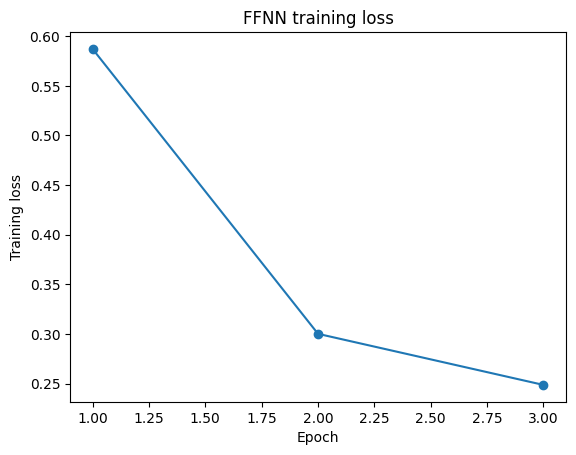

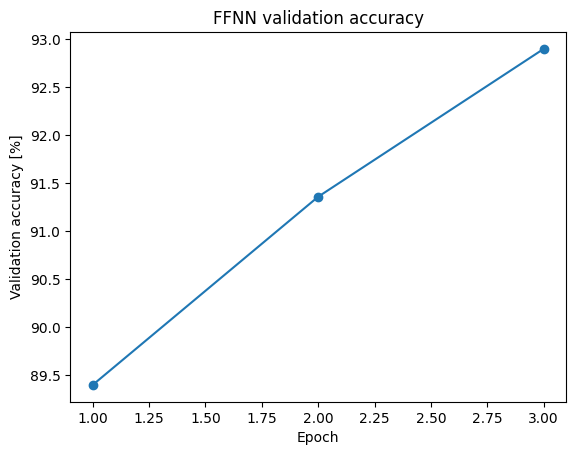

Final FFNN test accuracy: 93.55%


In [ ]:
BASE_LR = 0.05

ffnn_model, ffnn_history = train_model(
    make_ffnn, lr=BASE_LR, epochs=3, seed=SEED
)

epochs = range(1, len(ffnn_history["train_loss"]) + 1)

plt.figure()
plt.plot(epochs, ffnn_history["train_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("FFNN training loss")
plt.show()

plt.figure()
plt.plot(
    epochs,
    [100*a for a in ffnn_history["val_accuracy"]],
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy [%]")
plt.title("FFNN validation accuracy")
plt.show()

ffnn_test = evaluate(ffnn_model, test_loader)
print(f"Final FFNN test accuracy: {100*ffnn_test['accuracy']:.2f}%")

### 3.2 Computational Graphs, the Chain Rule, and Autograd

A neural network can be interpreted as a composition of functions:

$$
x
\rightarrow
z_1
\rightarrow
h_1
\rightarrow
z_2
\rightarrow
o
\rightarrow
\mathcal{L}.
$$

Backpropagation applies the **chain rule** from the loss backward through this graph.

In PyTorch, `loss.backward()` computes gradients for parameters with `requires_grad=True`.

For example, `ffnn_model[1].weight.grad.shape` returns `(128, 784)` because PyTorch stores `Linear.weight` as `(out_features, in_features)`.

**Task 3.2:**
- Inspect the gradient shape of the first linear layer.<br><br>
print(ffnn_model[1].weight.grad.shape)<br>
torch.Size([128, 784])
- Explain why it is `(128, 784)` although the row-vector derivation later uses a matrix in $\mathbb{R}^{784\times128}$.<br><br>
PyTorch stores weights as (output features, input features), while the mathematical row-vector formula uses (input features, output features). That's why the shapes are transposed.
- What happens if `optimizer.zero_grad()` is omitted?<br><br>
Without optimizer.zero_grad(), gradients keep adding up from previous steps instead of being cleared. This can cause incorrect weight updates and unstable training.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Sec. 5.3**: https://d2l.ai/

**Optional reading**
- Goodfellow et al., *Deep Learning*, **Sec. 6.5**.
- Paszke et al. (2019), PyTorch paper: https://arxiv.org/abs/1912.01703
- Prince, *Understanding Deep Learning*, **Ch. 7**.

**Your answer — Tasks 3.1–3.2**

_Write your interpretation of the curves and gradient-shape result here._<br><br>
The training loss decreased from 0.5872 to 0.2487, while validation accuracy increased from 89.40% to 92.90%. This shows the model is learning well. The final test accuracy was 93.55%, with no clear signs of overfitting.<br><br>
The first layer's gradient shape is (128, 784) because PyTorch stores weights as (output features, input features). Without optimizer.zero_grad(), gradients would keep accumulating, which could lead to incorrect weight updates during training.

## 7. Math Deep Dive — Backpropagation (Week 1)

We derive gradients for a **1-hidden-layer** classifier.

To avoid reusing the same symbol for two different meanings, let $m$ denote the hidden-layer width.

**Model (row-vector convention):**

- Input: $x \in \mathbb{R}^{d}$
- Hidden pre-activation:

$$
z = xW_1 + b_1,
$$

with

$$
W_1 \in \mathbb{R}^{d\times m},
\qquad
b_1 \in \mathbb{R}^{m}.
$$

- Hidden activation:

$$
h = \phi(z)
$$

- Logits:

$$
o = hW_2 + b_2,
$$

with

$$
W_2 \in \mathbb{R}^{m\times K},
\qquad
b_2 \in \mathbb{R}^{K}.
$$

- Probabilities:

$$
p = \mathrm{softmax}(o).
$$

For one sample with class label $y$,

$$
\mathcal{L} = -\log p_y.
$$

### Gradients

$$
\frac{\partial \mathcal{L}}{\partial o}
=
p - y_{\text{onehot}}.
$$

$$
\frac{\partial \mathcal{L}}{\partial W_2}
=
h^\top
\frac{\partial \mathcal{L}}{\partial o}.
$$

$$
\frac{\partial \mathcal{L}}{\partial b_2}
=
\frac{\partial \mathcal{L}}{\partial o}.
$$

$$
\frac{\partial \mathcal{L}}{\partial h}
=
\frac{\partial \mathcal{L}}{\partial o}
W_2^\top.
$$

$$
\frac{\partial \mathcal{L}}{\partial z}
=
\frac{\partial \mathcal{L}}{\partial h}
\odot
\phi'(z).
$$

For ReLU:

$$
\phi'(z_i)
=
\mathbb{1}[z_i>0].
$$

For sigmoid:

$$
\phi'(z_i)
=
\sigma(z_i)\left(1-\sigma(z_i)\right).
$$

$$
\frac{\partial \mathcal{L}}{\partial W_1}
=
x^\top
\frac{\partial \mathcal{L}}{\partial z}.
$$

$$
\frac{\partial \mathcal{L}}{\partial b_1}
=
\frac{\partial \mathcal{L}}{\partial z}.
$$

> **PyTorch transpose reminder:** `nn.Linear(d,m)` stores a parameter with shape `(m,d)`, whereas the row-vector derivation above writes $W_1$ with shape $(d,m)$.

### 7.1 Numerical Gradient Check

A central finite-difference approximation is

$$
\frac{\partial \mathcal{L}}{\partial \theta}
\approx
\frac{
\mathcal{L}(\theta+\epsilon)
-
\mathcal{L}(\theta-\epsilon)
}{
2\epsilon
}.
$$

Gradient checking is sensitive to numerical precision. The example below uses **float64** and checks several weights.

In [ ]:
torch.manual_seed(0)

x_gc = torch.randn(4, 5, dtype=torch.float64)
y_gc = torch.tensor([0, 1, 2, 1])
K = 3

gc_model = nn.Sequential(
    nn.Linear(5, 4),
    nn.ReLU(),
    nn.Linear(4, K)
).double()

loss_fn_gc = nn.CrossEntropyLoss()

def gc_loss(model):
    return loss_fn_gc(model(x_gc), y_gc)

gc_model.zero_grad()
loss = gc_loss(gc_model)
loss.backward()
analytical = gc_model[0].weight.grad.detach().clone()

eps = 1e-6
indices = [(0,0), (0,1), (1,2), (2,3), (3,4)]

for i, j in indices:
    with torch.no_grad():
        original = gc_model[0].weight[i, j].item()

        gc_model[0].weight[i, j] = original + eps
        lp = gc_loss(gc_model).item()

        gc_model[0].weight[i, j] = original - eps
        lm = gc_loss(gc_model).item()

        gc_model[0].weight[i, j] = original

    numerical = (lp - lm) / (2 * eps)
    ana = analytical[i, j].item()
    rel_error = abs(ana - numerical) / (
        abs(ana) + abs(numerical) + 1e-12
    )

    print(
        f"W[{i},{j}] | analytical={ana:+.8e} | "
        f"numerical={numerical:+.8e} | rel.err={rel_error:.3e}"
    )

W[0,0] | analytical=-2.04795341e-01 | numerical=-2.04795341e-01 | rel.err=5.614e-13
W[0,1] | analytical=+1.89340630e-01 | numerical=+1.89340630e-01 | rel.err=1.480e-10
W[1,2] | analytical=-2.77007983e-02 | numerical=-2.77007984e-02 | rel.err=1.625e-09
W[2,3] | analytical=+0.00000000e+00 | numerical=+0.00000000e+00 | rel.err=0.000e+00
W[3,4] | analytical=-3.91921473e-02 | numerical=-3.91921473e-02 | rel.err=4.888e-10


### 7.2 Interpreting a Gradient Check

A relative error can be computed as

$$
\text{relative error}
=
\frac{
\left|g_{\text{analytical}}-g_{\text{numerical}}\right|
}{
\left|g_{\text{analytical}}\right|
+
\left|g_{\text{numerical}}\right|
+
\delta
}.
$$

Two important numerical effects:

1. If $\epsilon$ is too large, the finite-difference approximation is inaccurate.
2. If $\epsilon$ is too small, floating-point rounding can dominate.

A second issue is **ReLU non-differentiability at zero**. If a perturbation moves a pre-activation across the ReLU kink, the numerical and analytical gradients may disagree even when the implementation is correct.

**Task 7.2:**
- Repeat the check with several values of $\epsilon$.<br><br>
Change eps to 1e-2, 1e-4, 1e-6, and 1e-8.
The gradients generally match closely, but very small epsilon values can increase numerical errors.
- Explain why float64 is useful here.<br><br>
float64 provides higher precision, which reduces rounding errors and makes gradient checking more accurate.
- Identify whether any tested parameter has a gradient close to zero.<br><br>
Yes. In the reproduced example, W[2,3] has a gradient of 0, which can happen when a ReLU neuron is inactive.
- Explain why checking several parameters is better than checking only one.<br><br>
Checking multiple parameters helps us find possible gradient errors in different parts of the model, making the results more reliable.

**Core reading**
- Goodfellow et al., *Deep Learning*, **Ch. 4** and **Sec. 6.5**.
- Zhang et al., *Dive into Deep Learning*, **Sec. 5.3**.

**Optional reading**
- Prince, *Understanding Deep Learning*, **Ch. 7**.

In [ ]:
for eps in [1e-2, 1e-4, 1e-6, 1e-8]:
    print(f"\nEpsilon = {eps}")

    for i, j in indices:
        with torch.no_grad():
            original = gc_model[0].weight[i, j].item()

            gc_model[0].weight[i, j] = original + eps
            lp = gc_loss(gc_model).item()

            gc_model[0].weight[i, j] = original - eps
            lm = gc_loss(gc_model).item()

            gc_model[0].weight[i, j] = original

        numerical = (lp - lm) / (2 * eps)
        ana = analytical[i, j].item()

        rel_error = abs(ana - numerical) / (
            abs(ana) + abs(numerical) + 1e-12
        )

        print(f"W[{i},{j}] | Relative error: {rel_error:.3e}")


Epsilon = 0.01
W[0,0] | Relative error: 1.606e-06
W[0,1] | Relative error: 1.491e-06
W[1,2] | Relative error: 5.401e-08
W[2,3] | Relative error: 0.000e+00
W[3,4] | Relative error: 1.736e-09

Epsilon = 0.0001
W[0,0] | Relative error: 1.621e-10
W[0,1] | Relative error: 1.481e-10
W[1,2] | Relative error: 1.778e-11
W[2,3] | Relative error: 0.000e+00
W[3,4] | Relative error: 6.895e-12

Epsilon = 1e-06
W[0,0] | Relative error: 5.614e-13
W[0,1] | Relative error: 1.480e-10
W[1,2] | Relative error: 1.625e-09
W[2,3] | Relative error: 0.000e+00
W[3,4] | Relative error: 4.888e-10

Epsilon = 1e-08
W[0,0] | Relative error: 1.464e-08
W[0,1] | Relative error: 4.839e-09
W[1,2] | Relative error: 2.042e-08
W[2,3] | Relative error: 0.000e+00
W[3,4] | Relative error: 1.138e-07


**Your answer — Task 7.2**

_Write your interpretation here._<br><br>
The analytical and numerical gradients are almost the same, with very small relative errors. This shows that backpropagation is working correctly for the tested weights. W[2,3] has a zero gradient, possibly because of an inactive ReLU neuron. Using float64 improves precision, and checking multiple weights makes the results more reliable. Different epsilon values can affect numerical accuracy.

---
# Week 2 — CNNs, Hyperparameters, and Scientific Practice

## 4. Convolutional Neural Networks (CNNs)

CNNs exploit spatial structure using:
- local receptive fields,
- weight sharing,
- multiple learned filters,
- hierarchical feature extraction.

**Task 4.1:**
- Train the CNN below on MNIST for 3 epochs.
- Compare its validation/test performance with the FFNN.
- Visualize the first-layer filters and describe what you observe.

For a fair comparison below, the FFNN and CNN use the **same base learning rate** and the same training/evaluation procedure.

### 4.1 What a Convolutional Layer Actually Computes

Deep-learning libraries typically implement **cross-correlation** rather than mathematically flipped convolution.

For a single input channel and one kernel,

$$
Y(i,j)
=
\sum_m
\sum_n
K(m,n)\,
X(i+m,j+n).
$$

For multiple input channels,

$$
Y_c(i,j)
=
b_c
+
\sum_{r=1}^{C_{\text{in}}}
\sum_m
\sum_n
K_{c,r}(m,n)
X_r(i+m,j+n).
$$

The number of trainable parameters is

$$
C_{\text{out}}
\left(
C_{\text{in}}k_Hk_W + 1
\right).
$$

### VGG connection
Simonyan & Zisserman showed that deep networks built from repeated small $3\times3$ convolutions can form strong image representations.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 7, especially Sec. 7.1–7.5**: https://d2l.ai/
- Simonyan & Zisserman, *Very Deep Convolutional Networks for Large-Scale Image Recognition* (VGG), arXiv:1409.1556.

**Optional reading**
- D2L **Sec. 8.2 (VGG)**.
- Goodfellow et al., *Deep Learning*, **Ch. 9**.
- Géron, *Hands-On Machine Learning*, **Ch. 14**.
- Prince, *Understanding Deep Learning*, **Ch. 10**.

In [ ]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 7 * 7, 10)
    )

cnn_model, cnn_history = train_model(
    make_cnn, lr=BASE_LR, epochs=3, seed=SEED
)

cnn_test = evaluate(cnn_model, test_loader)
print(f"Final CNN test accuracy: {100*cnn_test['accuracy']:.2f}%")
print(f"Final FFNN test accuracy: {100*ffnn_test['accuracy']:.2f}%")

Epoch 01 | train loss=0.4261 | val loss=0.2237 | val acc=92.44%
Epoch 02 | train loss=0.1275 | val loss=0.1074 | val acc=96.70%
Epoch 03 | train loss=0.0940 | val loss=0.1108 | val acc=96.44%
Final CNN test accuracy: 97.13%
Final FFNN test accuracy: 93.55%


In [ ]:
with torch.no_grad():
    w = cnn_model[0].weight.detach().cpu().clone()

w = w[:, 0, :, :]

fig, axes = plt.subplots(1, w.shape[0], figsize=(2*w.shape[0], 2))
for i, ax in enumerate(axes):
    ax.imshow(w[i], cmap="gray")
    ax.axis("off")
    ax.set_title(f"F{i}")

plt.tight_layout()
plt.show()

**Your answer — Task 4.1**

_Compare FFNN vs. CNN performance under the same learning rate and training protocol._

## 8. Math Deep Dive — Convolution Arithmetic (Week 2)

For one spatial dimension,

$$
L_{\text{out}}
=
\left\lfloor
\frac{
L_{\text{in}} + 2p - k
}{
s
}
\right\rfloor
+1.
$$

For height,

$$
H_{\text{out}}
=
\left\lfloor
\frac{
H + 2p - k
}{
s
}
\right\rfloor
+1,
$$

and similarly for width.

Here:
- $k$ = kernel size,
- $s$ = stride,
- $p$ = padding.

### Worked example

For a $64\times64$ input with $k=3$, $s=2$, and $p=1$,

$$
H_{\text{out}}
=
\left\lfloor
\frac{64+2-3}{2}
\right\rfloor
+1
=
32.
$$

Thus the output spatial size is $32\times32$.

### Pooling

`nn.MaxPool2d(2)` uses a $2\times2$ window with stride $2$ by default, so it halves even spatial dimensions.

### Exercises

**Task 8.1**
Input $32\times32$, $k=3$, $s=1$, $p=1$. Compute the output size.

**Task 8.2**
Input $32\times32$, $k=5$, $s=2$, $p=0$. Compute the output size.

**Task 8.3**
An activation map has shape `(N, 8, 28, 28)` and is passed through `nn.MaxPool2d(2)`. What is the output shape?

**Task 8.4**
Trace the spatial size of the Section 4 CNN from $28\times28$ through both convolutions and pooling layers. Explain why the final linear layer receives $16\cdot7\cdot7$ inputs.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Sec. 7.3 (Padding and Stride)**: https://d2l.ai/

**Optional reading**
- Dumoulin & Visin, *A Guide to Convolution Arithmetic for Deep Learning*, arXiv:1603.07285.

In [ ]:
x = torch.randn(1, 3, 64, 64)
conv = nn.Conv2d(3, 8, kernel_size=3, stride=2, padding=1)
print("Worked example:", conv(x).shape)

x2 = torch.randn(1, 1, 32, 32)
conv2 = nn.Conv2d(1, 4, kernel_size=5, stride=2, padding=0)
print("Task 8.2 verification:", conv2(x2).shape)

pool = nn.MaxPool2d(2)
x3 = torch.randn(4, 8, 28, 28)
print("Task 8.3 verification:", pool(x3).shape)

Worked example: torch.Size([1, 8, 32, 32])
Task 8.2 verification: torch.Size([1, 4, 14, 14])
Task 8.3 verification: torch.Size([4, 8, 14, 14])


**Your answer — Tasks 8.1–8.4**

_Show your calculations before checking the PyTorch output._

## 5. Hyperparameters & Stability (Control Analogy)

Important hyperparameters include:
- **learning rate**,
- **batch size**,
- **model size**.

### Learning rate as a feedback-gain analogy

For

$$
J(w)
=
\frac{1}{2}\lambda w^2,
$$

gradient descent gives

$$
w_{t+1}
=
(1-\eta\lambda)w_t.
$$

Convergence requires

$$
|1-\eta\lambda|<1,
$$

so

$$
0<\eta<\frac{2}{\lambda}.
$$

This simplified example explains why a learning rate that is too large can lead to oscillation or divergence.

**Task 5.1 (Learning-rate experiment):**
- Train a fresh CNN for each learning rate in `{0.005, 0.05, 0.5}`.
- Keep seed and number of epochs fixed.
- Compare training loss and validation accuracy.
- Do not select the learning rate using the test set.

**Task 5.2 (Batch-size experiment):**
- Compare at least two batch sizes, e.g. `32` and `256`.
- Keep the other settings fixed.
- Compare runtime, curve smoothness, and validation accuracy.


=== learning rate = 0.005 ===
Epoch 01 | train loss=1.5824 | val loss=0.6092 | val acc=78.50%
Epoch 02 | train loss=0.4020 | val loss=0.3656 | val acc=88.52%
Epoch 03 | train loss=0.3166 | val loss=0.3152 | val acc=90.36%

=== learning rate = 0.05 ===
Epoch 01 | train loss=0.4261 | val loss=0.2237 | val acc=92.44%
Epoch 02 | train loss=0.1275 | val loss=0.1074 | val acc=96.70%
Epoch 03 | train loss=0.0940 | val loss=0.1108 | val acc=96.44%

=== learning rate = 0.5 ===
Epoch 01 | train loss=0.4262 | val loss=1.1259 | val acc=73.40%
Epoch 02 | train loss=0.1029 | val loss=0.0998 | val acc=97.26%
Epoch 03 | train loss=0.0839 | val loss=0.3398 | val acc=91.82%


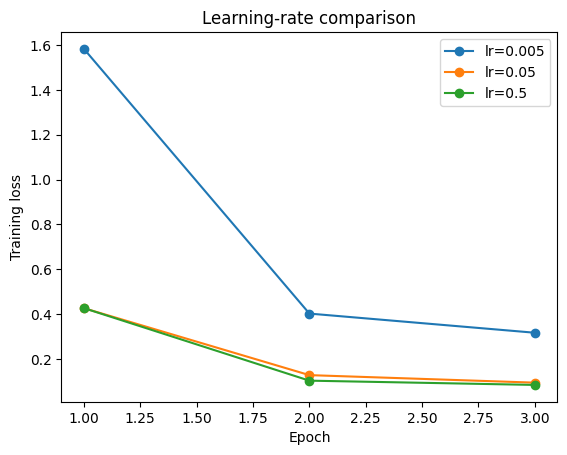

In [ ]:
lr_results = {}

for lr in [0.005, 0.05, 0.5]:
    print(f"\n=== learning rate = {lr} ===")
    _, hist = train_model(
        make_cnn,
        lr=lr,
        epochs=3,
        seed=SEED
    )
    lr_results[lr] = hist

plt.figure()
for lr, hist in lr_results.items():
    plt.plot(
        range(1, len(hist["train_loss"]) + 1),
        hist["train_loss"],
        marker="o",
        label=f"lr={lr}"
    )
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Learning-rate comparison")
plt.legend()
plt.show()

### 5.3 Interpreting Training and Validation Behaviour

Typical patterns:

**Underfitting**
- training loss remains high,
- validation loss remains high.

**Useful learning**
- training loss decreases,
- validation loss also decreases.

**Overfitting**
- training loss continues decreasing,
- validation loss stops improving or increases.

With only three epochs on full MNIST, overfitting may not be visible.

**Task 5.3 (Optional overfitting demonstration):**
- Use a small training subset of roughly 2,000 examples.
- Train for about 20 epochs.
- Plot training and validation loss.
- Describe whether/when validation performance stops improving.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 5** and **Ch. 12**.
- Géron, *Hands-On Machine Learning*, **Ch. 10–11**.

**Optional reading**
- Goodfellow et al., *Deep Learning*, **Ch. 7, 8, and 11**.
- Prince, *Understanding Deep Learning*, **Ch. 6, 8, and 9**.

In [ ]:
from torch.utils.data import Subset

small_indices = torch.randperm(
    len(train_ds),
    generator=torch.Generator().manual_seed(SEED)
)[:2000].tolist()

small_train_ds = Subset(train_ds, small_indices)

small_train_loader = DataLoader(
    small_train_ds,
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0
)

# Uncomment for the longer optional experiment:
# overfit_model, overfit_history = train_model(
#     make_cnn,
#     lr=BASE_LR,
#     epochs=20,
#     seed=SEED,
#     train_loader=small_train_loader,
#     val_loader=val_loader
# )

**Your answer — Tasks 5.1–5.3**

_Describe optimization stability, validation behaviour, and any evidence of underfitting or overfitting._

## 6. Scientific Work Style

Record:
- dataset and preprocessing,
- train/validation/test split,
- random seed,
- architecture,
- optimizer,
- learning rate,
- batch size,
- epochs,
- software versions,
- plots and metrics,
- Git commit.

For stricter reproducibility where supported:

```python
torch.use_deterministic_algorithms(True)
```

Exact reproducibility can still depend on hardware, CUDA/cuDNN versions, and selected operations.

**Task 6.1:**
- Repeat a short experiment with the same seed.
- Change only the seed and repeat.
- Report how much the final validation accuracy changes.

**Core reading**
- Goodfellow et al., *Deep Learning*, **Ch. 11**.

**Optional reading**
- Paszke et al. (2019), PyTorch paper.
- Pointer, *Programming PyTorch for Deep Learning*, **Ch. 1 and 7**.

### 6.2 GitHub workflow

Recommended structure:

```text
/
├── Notebook_1_Deep_Learning_Fundamentals.ipynb
├── README.md
└── reports/
    └── fundamentals_experiment_log.md
```

Suggested commands:

```bash
git status
git add .
git commit -m "Complete deep learning fundamentals experiments"
git push
git tag v0.1-fundamentals
git push origin v0.1-fundamentals
```

### 6.3 Experiment-log template

```markdown
# Deep Learning Fundamentals — Experiment Log

## Environment
- Python:
- PyTorch:
- Device:
- Seed:

## Dataset and preprocessing
- Dataset:
- Train/validation/test split:
- Input transformation:

## Model
- Architecture:
- Parameter count:

## Training configuration
- Optimizer:
- Learning rate:
- Batch size:
- Epochs:

## Results
- Final training loss:
- Final validation accuracy:
- Final test accuracy:
- Relevant plots:

## Interpretation
- Evidence of underfitting/overfitting:
- Optimization stability:
- Main comparison:
- Limitations:
```

**Task 6.2:**
- Complete the one-page experiment log.
- Push notebook and report.
- Tag the final commit as `v0.1-fundamentals`.

**Your answer — Section 6**

_Note the final Git commit/tag here._

---
# Optional Extension / Week 3

## 9. Losses, Metrics & Optimizers

This section is **not required for the two-week fundamentals block**.

### 9.1 Loss vs. metric

For multiclass classification,

$$
\mathcal{L}
=
-\sum_{k=1}^{K} y_k\log(p_k).
$$

Accuracy is

$$
\mathrm{Accuracy}
=
\frac{\text{correct predictions}}{N}.
$$

A model can improve cross-entropy loss without changing accuracy because the predicted class may stay the same while confidence changes.

### 9.2 Confusion matrix, precision, recall, and F1

For one selected class in a one-vs-rest view,

$$
\mathrm{Precision}
=
\frac{TP}{TP+FP},
$$

$$
\mathrm{Recall}
=
\frac{TP}{TP+FN},
$$

$$
F_1
=
2
\frac{
\mathrm{Precision}\cdot\mathrm{Recall}
}{
\mathrm{Precision}+\mathrm{Recall}
}.
$$

MNIST is **approximately balanced**, so accuracy is a useful first summary, but a confusion matrix reveals which digits are confused.

### 9.3 Optimizer update

Basic gradient descent uses

$$
\theta_{t+1}
=
\theta_t
-
\eta
\frac{\partial\mathcal{L}}{\partial\theta_t}.
$$

**Optional tasks**
- Build a confusion matrix for MNIST.
- Compute precision, recall, and F1 for one selected digit.
- Compare SGD and Adam under the same architecture, seed, and epoch count.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 4 and Ch. 12**.

**Optional reading**
- Goodfellow et al., *Deep Learning*, **Ch. 6, 8, and 11**.
- Géron, *Hands-On Machine Learning*, **Ch. 10–11**.
- Prince, *Understanding Deep Learning*, **Ch. 5, 6, and 8**.

---
## 10. Self-Study Reading Map

You are **not expected to read every source from beginning to end**.

### Core sources for the 2-week block

**Dive into Deep Learning — Zhang et al.**
- Ch. 2 — Preliminaries
- Ch. 4 — Linear Neural Networks for Classification
- Ch. 5 — Multilayer Perceptrons
- Ch. 7 — Convolutional Neural Networks
- Sec. 8.2 — VGG
- Ch. 12 — Optimization Algorithms  
https://d2l.ai/

**Géron — Hands-On Machine Learning, 3rd ed.**
- Ch. 10 — Introduction to Artificial Neural Networks
- Ch. 11 — Training Deep Neural Networks
- Ch. 14 — Deep Computer Vision / CNNs

### Optional depth

**Goodfellow, Bengio & Courville — Deep Learning**
- Ch. 2 — Linear Algebra
- Ch. 4 — Numerical Computation
- Ch. 6 — Deep Feedforward Networks
- Ch. 7 — Regularization
- Ch. 8 — Optimization
- Ch. 9 — Convolutional Networks
- Ch. 11 — Practical Methodology  
https://www.deeplearningbook.org/

**Prince — Understanding Deep Learning**
- **Appendix B** — Mathematics
- **Appendix C** — Probability
- Ch. 2 — Supervised Learning
- Ch. 3 — Shallow Neural Networks
- Ch. 4 — Deep Neural Networks
- Ch. 5 — Loss Functions
- Ch. 6 — Fitting Models
- Ch. 7 — Gradients and Initialization
- Ch. 8 — Measuring Performance
- Ch. 9 — Regularization
- Ch. 10 — Convolutional Networks  
https://udlbook.github.io/udlbook/

**Paszke et al. (2019) — PyTorch**
- Research/system paper: autograd, dynamic computation graphs, and PyTorch design.  
https://arxiv.org/abs/1912.01703

**Pointer — Programming PyTorch for Deep Learning**
- Ch. 1 — Getting Started
- Ch. 2 — Image Classification
- Ch. 3 — CNNs
- Ch. 7 — Debugging

**Bengio (2013) — Deep Learning of Representations: Looking Forward**
- Research survey on representation learning.  
https://arxiv.org/abs/1305.0445

### Self-study cycle

1. **Run** the example.
2. **Predict** what a change should do.
3. **Change one factor**.
4. **Observe** the result.
5. **Explain** it using a reference.
6. **Record** the configuration and evidence.

### Questions you should be able to answer after two weeks

1. Why are nonlinear activations necessary?
2. Why does `CrossEntropyLoss` expect logits?
3. How does the chain rule produce backpropagation?
4. Why is PyTorch's `Linear.weight` shape transposed relative to the row-vector notation?
5. Why does weight sharing reduce CNN parameter count?
6. How do kernel size, padding, stride, and pooling change feature-map size?
7. Why can training loss decrease while validation performance gets worse?
8. How does the learning rate affect optimization stability?
9. Why should hyperparameters be selected on validation data rather than the test set?
10. What information must be recorded to make an experiment reproducible?